In [76]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [77]:
column_names = [
    'preg', 'plas', 'pres', 'skin', 'test',
    'mass', 'pedi', 'age', 'class'
]

In [78]:
df = pd.read_csv("pima-indians-diabetes.csv", names=column_names)
df.head()

,preg,plas,pres,skin,test,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [79]:
X = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [80]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

In [81]:
base_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
base_model.fit(X_train, y_train)
y_pred_base = base_model.predict(X_test)

print("Accuracy: ", accuracy_score(y_test, y_pred_base))

Accuracy:  0.7727272727272727


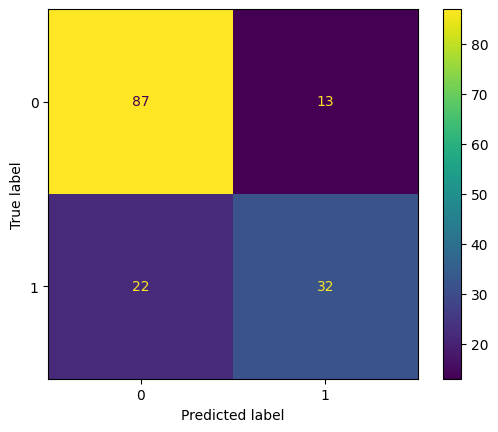

In [82]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_base)

In [83]:
param_grid = {
    "n_estimators" : [50, 100, 125],
    "learning_rate": [0.25, 0.05, 1],
    "max_depth": [2,3,4,None],
    "subsample": [0.8, 1.0]
}

In [84]:
r_grid = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions = param_grid,
    scoring="accuracy",
    cv = 3,
    n_iter=15,
    n_jobs=1
)


In [85]:
r_grid.fit(X_train, y_train)
print("Best parameters:", r_grid.best_params_)
print("Best CV Accuracy:", round(r_grid.best_score_, 2))

Best parameters: {'subsample': 0.8, 'n_estimators': 125, 'max_depth': 3, 'learning_rate': 0.05}
Best CV Accuracy: 0.78


In [86]:
best_r_mod = r_grid.best_estimator_
y_r_pred = best_r_mod.predict(X_test)
print("Best Model Accuracy Score according to randomisedSearchCV: ", round(best_r_mod.score(X_test, y_test), 3))

Best Model Accuracy Score according to randomisedSearchCV:  0.766


In [87]:
grid = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid = param_grid,
    scoring="accuracy",
    cv = 3,
    n_jobs=1
)

In [88]:
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Best CV Accuracy:", round(grid.best_score_, 2))

Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 125, 'subsample': 0.8}
Best CV Accuracy: 0.78


In [89]:
best_g_mod = grid.best_estimator_
y_g_pred = best_g_mod.predict(X_test)
print("Best Model Accuracy Score according to GridSearchCV: ", round(best_g_mod.score(X_test, y_test), 3))

Best Model Accuracy Score according to GridSearchCV:  0.766


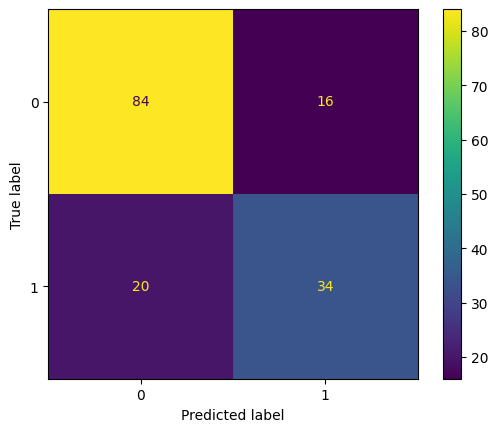

In [90]:
ConfusionMatrixDisplay.from_predictions(y_test, y_r_pred)

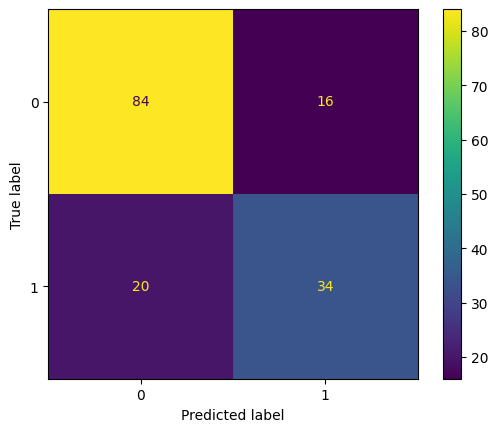

In [91]:
ConfusionMatrixDisplay.from_predictions(y_test, y_g_pred)